> **⚠️ OUTDATED (2026-07-16) — xem trước khi chạy lại**
>
> Notebook này hiển thị `alpha_score` cùng các cột `momentum_score`/`rs_score`/`trend_score`/`liquidity_score`
> như thể `alpha_score` được dẫn dắt bởi các nhân tố đó (tư duy v1). Từ `docs/reports/scoring/SCORE_V2_REPORT.md`, `alpha_score`
> hiện tại (v2) chỉ là 70% `realized_vol_20d` + 30% `value_ma20` — các cột momentum/trend/rs ở đây thuộc về
> `alpha_score_shadow_v1` (composite cũ, giữ lại để so sánh, không phải cơ sở của `alpha_score`).
>
> Xem thêm: `docs/reports/scoring/SCORE_V2_REPORT.md` mục "Trạng thái sau GĐ5" (v2 hiện chỉ chạy shadow, KHÔNG dùng vốn thật) và
> `docs/reports/scoring/WATCHLIST_VALIDATION_REPORT.md` (composite/`risk_score` đã kiểm định, kết quả âm tính/trùng lặp).
>
> **Không sửa nội dung notebook trong round này** — chỉ cảnh báo trước khi dùng lại kết quả.

# 12 — Meta Ranking & Alpha Scoring

Notebook này kết hợp các tín hiệu và điểm số để xếp hạng danh mục cổ phiếu tiềm năng.

In [3]:
# Cell: Setup Project Root
import os
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().resolve().parents[0] if Path.cwd().name == "notebooks" else Path.cwd().resolve()
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

PROJECT_ROOT

PosixPath('/Users/jamesb/Desktop/vietnam-quant-research')

In [4]:
# Cell: Import Meta Ranking Helpers
from pathlib import Path

import numpy as np
import pandas as pd

from src.analytics.meta_ranking import build_meta_ranking, top_meta_candidates, save_meta_ranking_outputs
from src.data.loaders import read_parquet
from src.reporting.chart_factory import (
    meta_component_heatmap,
    meta_priority_bucket_chart,
    meta_score_bar_chart,
    meta_symbol_component_chart,
)
from src.screening.light_market_scan import load_auto_watchlist_symbols


In [5]:
# Cell: Load Meta Inputs
features_path = Path("data/signals/setup_signals.parquet")
trade_cards_path = Path("data/signals/breakout_20d_trade_cards.parquet")
stealth_path = Path("data/signals/stealth_accumulation_latest.parquet")

features = read_parquet(features_path)
trade_cards = read_parquet(trade_cards_path)
stealth_latest = read_parquet(stealth_path)

feature_symbol_set = set(features["symbol"].astype(str).str.upper()) if not features.empty and "symbol" in features.columns else set()
trade_symbol_set = set(trade_cards["symbol"].astype(str).str.upper()) if not trade_cards.empty and "symbol" in trade_cards.columns else set()
stealth_symbol_set = set(stealth_latest["symbol"].astype(str).str.upper()) if not stealth_latest.empty and "symbol" in stealth_latest.columns else set()

diagnostic = {
    "features_symbols": int(features["symbol"].nunique()) if "symbol" in features.columns and not features.empty else 0,
    "trade_card_symbols": int(trade_cards["symbol"].nunique()) if "symbol" in trade_cards.columns and not trade_cards.empty else 0,
    "stealth_symbols": int(stealth_latest["symbol"].nunique()) if "symbol" in stealth_latest.columns and not stealth_latest.empty else 0,
}
print(diagnostic)


{'features_symbols': 499, 'trade_card_symbols': 499, 'stealth_symbols': 3}


In [6]:
# Cell: Build Meta Ranking
ranked = build_meta_ranking(
    features,
    trade_cards,
    stealth_latest,
    signal_col="breakout_20d",
)
watchlist = top_meta_candidates(ranked, top_n=20, min_score=50.0)
prime = top_meta_candidates(
    ranked,
    top_n=10,
    min_score=75.0,
)

print({
    "ranked_rows": len(ranked),
    "watchlist_symbols": int(watchlist["symbol"].nunique()) if not watchlist.empty else 0,
    "prime_symbols": int(prime["symbol"].nunique()) if not prime.empty else 0,
})


{'ranked_rows': 499, 'watchlist_symbols': 4, 'prime_symbols': 0}


/Users/jamesb/Desktop/vietnam-quant-research/src/analytics/meta_ranking.py:212: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  .combine_first(_series_or_default(merged, "stealth_close", np.nan))


In [7]:
# Cell: Review Top Candidates
review_cols = [
    col
    for col in [
        "meta_rank",
        "symbol",
        "meta_score",
        "priority_bucket",
        "setup_style",
        "trade_edge_score",
        "net_accumulation_score",
        "momentum_component_score",
        "risk_penalty_score",
        "meta_summary",
    ]
    if col in ranked.columns
]
display(ranked[review_cols].head(10))
display(watchlist[review_cols].head(10))

,meta_rank,symbol,meta_score,priority_bucket,setup_style,trade_edge_score,net_accumulation_score,momentum_component_score,risk_penalty_score,meta_summary
0,1,BID,61.131703,High Conviction Watchlist,Momentum-led,0,67.171062,71.620149,17.433333,"BID: meta score 61.1/100, phong cách Momentum-..."
1,2,SAB,59.710793,Secondary Watchlist,Momentum-led,0,71.315483,84.067283,6.100000,"SAB: meta score 59.7/100, phong cách Momentum-..."
2,3,ASP,57.959447,Secondary Watchlist,Breakout-led,75,0.000000,97.579279,33.000000,"ASP: meta score 58.0/100, phong cách Breakout-..."
3,4,VPI,53.730420,Secondary Watchlist,Developing / Mixed,0,65.759453,63.191411,14.489610,"VPI: meta score 53.7/100, phong cách Developin..."
4,5,STB,43.840885,Low Priority,Momentum-led,0,0.000000,95.000347,33.000000,"STB: meta score 43.8/100, phong cách Momentum-..."
5,6,MSB,42.936548,Low Priority,Momentum-led,0,0.000000,88.917576,33.000000,"MSB: meta score 42.9/100, phong cách Momentum-..."
6,7,VAB,42.600549,Low Priority,Momentum-led,0,0.000000,88.124109,33.000000,"VAB: meta score 42.6/100, phong cách Momentum-..."
7,8,OCB,42.326235,Low Priority,Momentum-led,0,0.000000,91.487919,33.000000,"OCB: meta score 42.3/100, phong cách Momentum-..."
8,9,VCG,42.308108,Low Priority,Momentum-led,0,0.000000,84.581474,33.000000,"VCG: meta score 42.3/100, phong cách Momentum-..."
9,10,KLB,42.220109,Low Priority,Momentum-led,0,0.000000,94.714584,33.000000,"KLB: meta score 42.2/100, phong cách Momentum-..."


,meta_rank,symbol,meta_score,priority_bucket,setup_style,trade_edge_score,net_accumulation_score,momentum_component_score,risk_penalty_score,meta_summary
0,1,BID,61.131703,High Conviction Watchlist,Momentum-led,0,67.171062,71.620149,17.433333,"BID: meta score 61.1/100, phong cách Momentum-..."
1,2,SAB,59.710793,Secondary Watchlist,Momentum-led,0,71.315483,84.067283,6.100000,"SAB: meta score 59.7/100, phong cách Momentum-..."
2,3,ASP,57.959447,Secondary Watchlist,Breakout-led,75,0.000000,97.579279,33.000000,"ASP: meta score 58.0/100, phong cách Breakout-..."
3,4,VPI,53.730420,Secondary Watchlist,Developing / Mixed,0,65.759453,63.191411,14.489610,"VPI: meta score 53.7/100, phong cách Developin..."


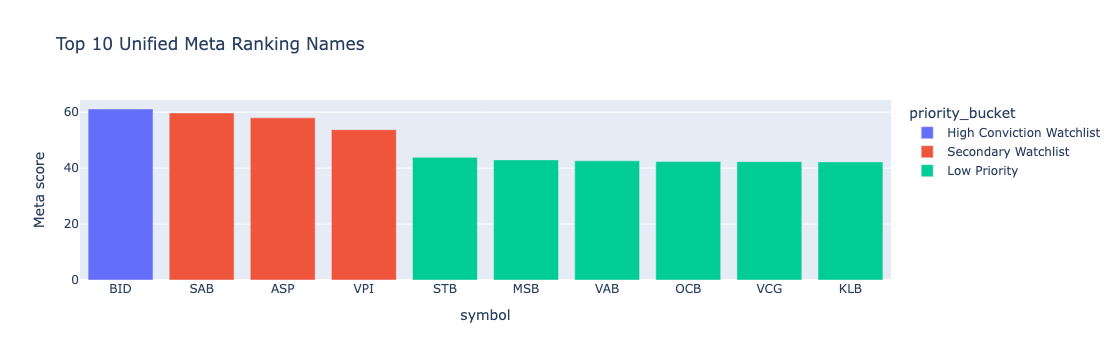

In [8]:
# Cell: Visualize Meta Leaders
meta_score_bar_chart(ranked, top_n=10, title="Top 10 Unified Meta Ranking Names")

In [9]:
# Cell: Review Bucket Distribution
meta_priority_bucket_chart(ranked, title="Meta Ranking Bucket Distribution")

In [10]:
# Cell: Compare Score Components
meta_component_heatmap(ranked, top_n=10, title="Meta Ranking Component Heatmap")

In [11]:
# Cell: Inspect Single Symbol Breakdown
focus_symbol = ranked.iloc[0]["symbol"] if not ranked.empty else "MBB"
print("focus_symbol:", focus_symbol)
meta_symbol_component_chart(ranked, symbol=focus_symbol, title="Meta Component Breakdown")

focus_symbol: BID


In [12]:
# Cell: Save Meta Ranking Outputs
save_meta_ranking_outputs(ranked, out_dir="data/signals")
print("Saved meta ranking outputs to data/signals/")


Saved meta ranking outputs to data/signals/


---
# Part 2 — Multi-Factor Alpha Research & Scoring System

Dưới đây là phần phân tích chấm điểm Alpha đa nhân tố (Multi-Factor Alpha Scoring) so với chỉ số VNINDEX, tính toán Rolling Beta và trực quan hóa hiệu quả sinh lời vượt trội.

# 12b — Alpha Research & Scoring System

Notebook này thực hiện tính toán điểm Alpha đa nhân tố (Multi-Factor Alpha Score) xếp hạng toàn bộ các mã cổ phiếu trên thị trường chứng khoán Việt Nam hàng ngày.

In [15]:
# Cell: Import Alpha Scoring Modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from src.data.loaders import read_parquet, save_parquet
from src.alpha.scoring import calculate_alpha_scores

In [16]:
# Cell: Load Inputs
# CUSTOMIZABLE: Define your custom watchlist here to filter alpha scoring analysis, or leave as None for full universe
user_watchlist = None  # e.g., ["SSI", "HPG", "FPT", "VIC"]
stock_df = read_parquet("data/processed/stock_features.parquet")
benchmark_df = read_parquet("data/processed/benchmark_vnindex.parquet")
if user_watchlist is not None:
    watchlist_upper = [sym.upper() for sym in user_watchlist]
    stock_df = stock_df[stock_df["symbol"].str.upper().isin(watchlist_upper)].copy()
    print(f"Using user custom watchlist for analysis: {watchlist_upper}")
print("Stock features rows:", len(stock_df))
print("Benchmark rows:", len(benchmark_df))

Stock features rows: 178493
Benchmark rows: 1614


In [17]:
# Cell: Compute Alpha Scores
print("Computing cross-sectional alpha scores...")
scored = calculate_alpha_scores(stock_df, benchmark_df)
save_parquet(scored, "data/signals/alpha_scores.parquet")
print("Saved scores database to data/signals/alpha_scores.parquet")

Computing cross-sectional alpha scores...
Saved scores database to data/signals/alpha_scores.parquet


In [18]:
# Cell: Compute Rolling Beta to Benchmark
from src.analytics.advanced import compute_rolling_beta

print("Computing rolling beta for all assets...")
scored_with_beta = compute_rolling_beta(scored, benchmark_df, window=60)
print("Beta calculation complete.")

Computing rolling beta for all assets...
Beta calculation complete.


In [19]:
# Cell: Show Latest Top Alpha Ranked Stocks with Beta
latest_date = scored_with_beta["date"].max()
latest_subset = scored_with_beta[scored_with_beta["date"] == latest_date].copy()

cols = [
    "symbol", "date", "close", "alpha_score", "momentum_score", 
    "rs_score", "trend_score", "volume_score", "volatility_score", 
    "liquidity_score", "rolling_beta_60d", "market_regime"
]
available_cols = [c for c in cols if c in latest_subset.columns]

ranking = latest_subset[available_cols].sort_values("alpha_score", ascending=False)
print(f"Latest date in database: {latest_date.strftime('%Y-%m-%d') if hasattr(latest_date, 'strftime') else latest_date}")
display(ranking.head(20))

Latest date in database: 2026-06-29


,symbol,date,close,alpha_score,momentum_score,rs_score,trend_score,volume_score,volatility_score,liquidity_score,rolling_beta_60d,market_regime
99102,NAB,2026-06-29,13100,79.128440,87.844037,50.229358,100.0,95.871560,72.477064,59.633028,NaN,uptrend
135558,STB,2026-06-29,75800,76.502294,92.660550,50.229358,100.0,89.908257,24.311927,97.247706,NaN,uptrend
155564,VCB,2026-06-29,62100,76.444954,65.825688,50.229358,100.0,88.532110,94.954128,93.119266,NaN,uptrend
124441,SAB,2026-06-29,48450,76.032110,76.376147,50.229358,100.0,83.486239,86.697248,63.761468,NaN,uptrend
117784,POW,2026-06-29,14850,75.091743,84.174312,50.229358,100.0,91.743119,34.403670,85.779817,NaN,uptrend
134480,SSB,2026-06-29,16100,74.977064,88.761468,50.229358,100.0,70.642202,61.926606,68.807339,NaN,uptrend
86215,KLB,2026-06-29,16400,74.541284,92.889908,50.229358,100.0,89.449541,33.027523,40.825688,NaN,uptrend
95881,MSB,2026-06-29,16000,74.415138,93.577982,50.229358,100.0,68.807339,37.614679,87.614679,NaN,uptrend
107538,OCB,2026-06-29,12450,73.738532,83.256881,50.229358,100.0,90.825688,28.899083,77.064220,NaN,uptrend
16282,ASP,2026-06-29,8910,72.385321,97.935780,50.229358,100.0,96.788991,5.963303,4.587156,NaN,uptrend


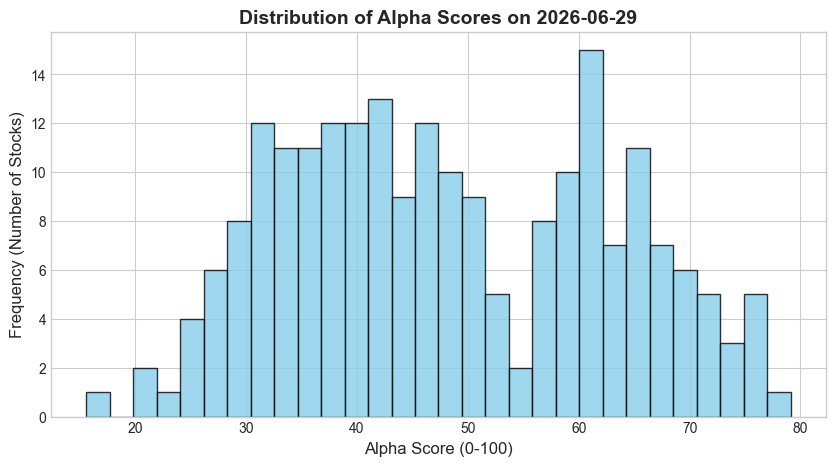

In [20]:
# Cell: Plot Score Distributions
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(ranking["alpha_score"], bins=30, color='skyblue', edgecolor='black', alpha=0.8)
ax.set_title(f"Distribution of Alpha Scores on {latest_date.strftime('%Y-%m-%d') if hasattr(latest_date, 'strftime') else latest_date}", fontsize=14, weight='bold')
ax.set_xlabel("Alpha Score (0-100)", fontsize=12)
ax.set_ylabel("Frequency (Number of Stocks)", fontsize=12)
plt.show()

## 1. Advanced Portfolio & Alpha Visualizations

Dưới đây là một bộ trực quan hóa đa chiều giúp phân tích động lượng (momentum), cấu phần nguồn alpha, rủi ro biến động, hệ số tương quan và cơ cấu danh mục để đưa ra quyết định đầu tư tối ưu.

### 1.1 Top 20 Alpha Scores
Biểu đồ cột hiển thị mức độ chênh lệch điểm số Alpha giữa các mã hàng đầu.

In [23]:
# Cell: Interactive Top Alpha Bar Chart
from src.reporting.chart_factory import top_alpha_bar_chart

fig_bar = top_alpha_bar_chart(ranking, top_n=20)
fig_bar.show()

### 1.2 Alpha Factor Breakdown Heatmap
Bản đồ nhiệt cấu phần điểm số giúp kiểm tra chất lượng điểm Alpha. Bạn có thể nhanh chóng xem mã cổ phiếu có điểm cao là nhờ dòng tiền (volume), động lượng (momentum), xu hướng giá (trend), hay do biến động thấp (volatility contraction).

In [25]:
# Cell: Interactive Alpha Factor Breakdown Heatmap
from src.reporting.chart_factory import alpha_factor_heatmap

fig_heatmap = alpha_factor_heatmap(ranking, top_n=20)
fig_heatmap.show()

### 1.3 Alpha Score vs Volatility Scatter Plot
Biểu đồ phân tán so sánh điểm Alpha với độ biến động (Annualized Volatility). Cổ phiếu lý tưởng nằm ở góc **trên-trái** (Alpha cao, Biến động thấp). Đường kẻ đỏ thể hiện mức biến động trung vị của toàn thị trường, đường kẻ xanh thể hiện ngưỡng Alpha mạnh (>=75).

In [27]:
# Cell: Interactive Alpha vs Volatility Scatter Plot
from src.reporting.chart_factory import alpha_vs_volatility_chart

fig_vol = alpha_vs_volatility_chart(scored_with_beta, date=latest_date)
fig_vol.show()

### 1.4 Alpha Score vs Beta Scatter Plot
So sánh điểm số Alpha với hệ số Beta (đo lường độ nhạy so với chỉ số VNINDEX). Giúp lọc ra những cổ phiếu có Alpha cao thực sự (alpha đặc trưng của doanh nghiệp) thay vì chỉ có Alpha giả tạo nhờ đòn bẩy thị trường (high beta).

In [29]:
# Cell: Interactive Alpha vs Beta Scatter Plot
from src.reporting.chart_factory import alpha_vs_beta_chart

fig_beta = alpha_vs_beta_chart(scored_with_beta, date=latest_date)
fig_beta.show()

### 1.5 Correlation Heatmap of Top 15 Alpha Stocks
Bản đồ tương quan Pearson dựa trên tỷ suất sinh lợi 120 phiên gần nhất của 15 cổ phiếu xếp hạng Alpha cao nhất. Một danh mục gồm các cổ phiếu có tương quan chéo thấp sẽ mang lại hiệu quả đa dạng hóa rủi ro tốt nhất.

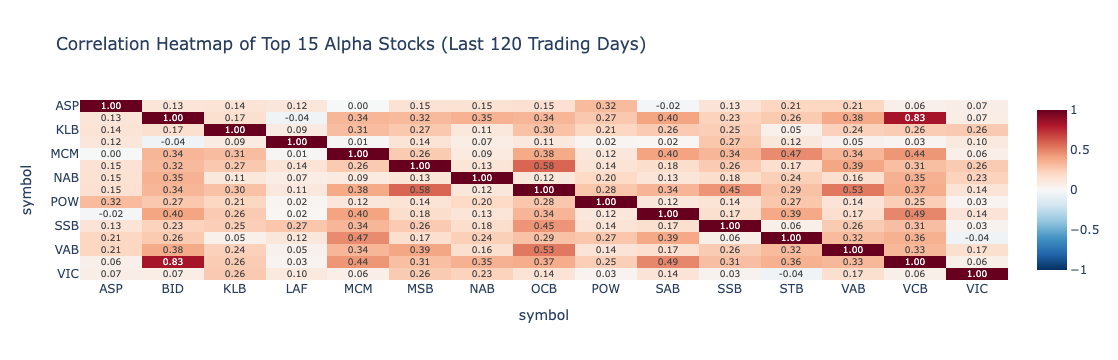

In [31]:
# Cell: Correlation Heatmap of Top Holdings
from src.reporting.chart_factory import correlation_heatmap

top_symbols = ranking["symbol"].head(15).tolist()
recent_df = scored_with_beta[scored_with_beta["symbol"].isin(top_symbols)].copy()
recent_df = recent_df.sort_values(["symbol", "date"])
recent_df = recent_df.groupby("symbol").tail(120)

return_matrix = recent_df.pivot_table(index="date", columns="symbol", values="return_1d", aggfunc="last")
corr_matrix = return_matrix.corr(method="pearson")

fig_corr = correlation_heatmap(corr_matrix, title="Correlation Heatmap of Top 15 Alpha Stocks (Last 120 Trading Days)")
fig_corr.show()

### 1.6 Historical Cumulative Returns of Top 5 Alpha Stocks
Đồ thị so sánh tỷ suất sinh lợi lũy kế của 5 cổ phiếu đứng đầu (được quy về mốc giá trị 100 tại ngày đầu tiên của chuỗi 120 phiên gần nhất). Giúp kiểm chứng độ bền bỉ và xu hướng giá của các siêu cổ phiếu.

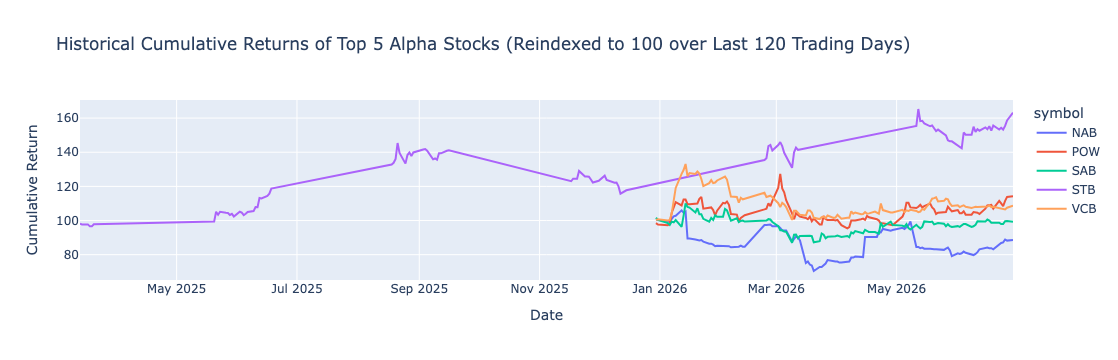

In [33]:
# Cell: Historical Cumulative Returns of Top 5 Alpha Stocks
import plotly.express as px

top_5_symbols = ranking["symbol"].head(5).tolist()
recent_stock_df = scored_with_beta[scored_with_beta["symbol"].isin(top_5_symbols)].copy()
recent_stock_df = recent_stock_df.groupby("symbol").tail(120)

cum_returns_list = []
for sym, gp in recent_stock_df.groupby("symbol"):
    gp = gp.sort_values("date").copy()
    gp["cum_return"] = (1.0 + gp["return_1d"].fillna(0.0)).cumprod() * 100
    cum_returns_list.append(gp[["date", "symbol", "cum_return"]])

cum_returns_df = pd.concat(cum_returns_list)
fig_cum = px.line(
    cum_returns_df,
    x="date",
    y="cum_return",
    color="symbol",
    title="Historical Cumulative Returns of Top 5 Alpha Stocks (Reindexed to 100 over Last 120 Trading Days)",
    labels={"cum_return": "Cumulative Return", "date": "Date"}
)
fig_cum.show()

In [34]:
# Cell: Export Reports
reports_dir = Path("reports")
reports_dir.mkdir(parents=True, exist_ok=True)

ranking.to_csv(reports_dir / "daily_alpha_ranking.csv", index=False)
ranking.head(20).to_csv(reports_dir / "top_watchlist.csv", index=False)
print(f"Exported reports to {reports_dir.resolve()}")

Exported reports to /Users/jamesb/Desktop/vietnam-quant-research/reports
